# Finding a Profitable Product for a New Etsy Shop
**Kat Chu**

This notebook uses data on the top 10,000 Etsy shops (by total sales, collected April 3, 2022) to answer three questions:

1. Which product categories have the strongest demand compared to how crowded they are?
2. Which shop features are related to higher sales?
3. Can a model predict whether a shop is a **top seller** (top 25% of sales in this group) from features a seller controls?

Every cleaning and modeling step in the white paper is done here so the results can be reproduced.

In [1]:
import glob, os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, RocCurveDisplay, balanced_accuracy_score)
pd.set_option('display.max_columns', 50)
FIG_DIR = '../images/' if os.path.isdir('../images') else ''
plt.rcParams['figure.dpi'] = 110

## 1. Load the data
The file is the Kaggle Etsy shop dataset (`etsy_04-03_Top10000_v2.csv`). The code looks for it on Kaggle first, then in the repository's `data/` folder or the notebook's folder. The file has some special characters that are not UTF-8, so it is read with `latin-1` encoding.

In [2]:
paths = (glob.glob('/kaggle/input/**/etsy_04-03_Top10000_v2.csv', recursive=True)
         + glob.glob('../data/etsy_04-03_Top10000_v2.csv') + glob.glob('data/etsy_04-03_Top10000_v2.csv')
         + glob.glob('etsy_04-03_Top10000_v2.csv'))
raw = pd.read_csv(paths[0], encoding='latin-1')
print('Rows, columns:', raw.shape)
raw.head(3)

Rows, columns: (10000, 36)


,shop_id,shop_name,url,shop_create_date,shop_update_date,digital_listing_count,digital_delivery_listing_count,is_open,seller_name,sold_count,additional_customization,active_listing_count,status,location,city,region,name,headline,favorites_count,average_rating,total_rating_count,average_rating_count,geoname_id,country_code,currency_code,has_currency_code,primary_language_id,accepts_direct_checkout,accepts_paypal,ships_to_country_ids,display_name,is_eligible_free_shipping,has_min_free_shipping,has_free_shipping,ships_to_regions,RunDate
0,9811209,PlannerKate1,https://www.etsy.com/shop/PlannerKate1,1406655490,1649003016,0,0,True,Kate Antesberger,1839198,True,2583,active,"Oak Harbor, Ohio",NaN,NaN,PlannerKate1,PlannerKate,61367,4.9869,239083,18880.0,5165215,US,USD,True,0,True,False,"[209, 0, 150, 79, 175]",Kate,False,False,False,['ANY'],4/3/2022 12:05
1,10204022,CaitlynMinimalist,https://www.etsy.com/shop/CaitlynMinimalist,1414883299,1649004834,0,0,True,Kate Kim,1565708,True,1070,active,"LA, California",NaN,NaN,CaitlynMinimalist,Dainty Personalized Jewelry crafted with Love ???,258218,4.8767,267763,113772.0,5368361,US,USD,True,0,True,False,"[79, 167, 290, 284, 209, 61, 58, 74, 105, 55, ...",Kate,True,False,True,['ANY'],4/3/2022 12:05
2,9901413,Beadboat1,https://www.etsy.com/shop/Beadboat1,1408476670,1649003805,0,0,True,Katy,1461640,True,8511,active,"Dallas, Texas",NaN,NaN,Beadboat1,"Jewelry supplies, Jewelry making, and everyday...",59085,4.7952,151056,59996.0,4684888,US,USD,True,0,True,False,"[70, 118, 146, 90, 151, 79, 207, 91, 71, 215, ...",Katy,True,True,True,"['AL', 'AM', 'AU', 'AT', 'BE', 'BG', 'BY', 'BR...",4/3/2022 12:05


## 2. First look: duplicates, missing values, and key numbers

In [3]:
print('Duplicate shop IDs:', raw['shop_id'].duplicated().sum())
print('Status values:', raw['status'].value_counts().to_dict())
missing = raw.isna().sum()
missing[missing > 0].sort_values(ascending=False)

Duplicate shop IDs: 0
Status values: {'active': 10000}


region                       7430
city                         7397
has_free_shipping            1446
ships_to_regions             1446
has_min_free_shipping        1446
is_eligible_free_shipping    1446
location                     1292
country_code                  973
headline                      494
average_rating                  7
average_rating_count            7
display_name                    1
dtype: int64

In [4]:
raw[['sold_count','active_listing_count','digital_listing_count','favorites_count',
     'average_rating','total_rating_count']].describe().round(2)

,sold_count,active_listing_count,digital_listing_count,favorites_count,average_rating,total_rating_count
count,10000.00,10000.00,10000.00,10000.00,9993.00,10000.00
mean,53484.19,851.31,165.38,7625.96,4.90,8471.47
std,62169.68,1855.14,624.90,9812.06,0.11,10895.58
min,22729.00,0.00,0.00,88.00,1.00,411.00
25%,28068.50,167.00,0.00,2388.00,4.87,3853.50
50%,36750.00,419.00,0.00,4744.00,4.92,5871.00
75%,56305.50,940.00,2.00,9247.50,4.96,9281.00
max,1839198.00,83954.00,22706.00,258218.00,5.00,267763.00


## 2b. Data source and verification checks
**Source:** Kaggle upload of Etsy shop data (Polartech, n.d.), not an official Etsy release. The Kaggle page does not fully document the collection method; the field names (for example `shop_id`, `ships_to_country_ids`, `is_eligible_free_shipping`) match Etsy's public shop data, so it was most likely gathered from public shop pages or Etsy's API by the uploader.

**Date range:** one snapshot. Collection started April 3, 2022 (`RunDate`), and shop records were last updated up to April 5, 2022, so it was gathered over about two days. `sold_count` is each shop's lifetime total up to that point. Shops in the file were created between 2010 and 2021.

Because I could not verify every value against Etsy, I ran consistency checks to see whether the data makes sense internally.

In [5]:
run_dt = pd.to_datetime(raw['RunDate'].iloc[0])
created = pd.to_datetime(raw['shop_create_date'], unit='s')
updated = pd.to_datetime(raw['shop_update_date'], unit='s')
checks = pd.Series({
    'Collection start (RunDate)': str(run_dt.date()),
    'Latest shop update in file': str(updated.max().date()),
    'Earliest / latest shop creation': f"{created.min().date()} / {created.max().date()}",
    'Shops created after collection date': int((created > run_dt).sum()),
    'Shops with more ratings than sales': int((raw['total_rating_count'] > raw['sold_count']).sum()),
    'Ratings outside 1-5': int(((raw['average_rating'] < 1) | (raw['average_rating'] > 5)).sum()),
    'Shops with 0 active listings': int((raw['active_listing_count'] == 0).sum()),
    'Shops with more digital than active listings': int((raw['digital_listing_count'] > raw['active_listing_count']).sum()),
    'All shops marked active/open': bool(raw['status'].eq('active').all() and raw['is_open'].all()),
    'Median ratings per sale': round((raw['total_rating_count'] / raw['sold_count']).median(), 3),
})
checks.to_frame('result')

,result
Collection start (RunDate),2022-04-03
Latest shop update in file,2022-04-05
Earliest / latest shop creation,2010-09-03 / 2021-11-11
Shops created after collection date,0
Shops with more ratings than sales,0
Ratings outside 1-5,0
Shops with 0 active listings,221
Shops with more digital than active listings,60
All shops marked active/open,True
Median ratings per sale,0.153


**What the checks show:** no impossible values (no shops created after the collection date, no shops with more ratings than sales, no ratings outside 1 to 5), and about 15 ratings per 100 sales, which is believable for online shopping. Two small quirks: 221 shops had 0 active listings at collection time (they may have been on break), and 60 shops show more digital listings than active listings. These shops are kept, and digital share is capped at 1 so the quirk does not distort the analysis.

## 3. Data cleaning and new features
Steps (all reproducible below):
1. Drop identity and text columns not needed for analysis (seller name, URL, display name, city, region, IDs).
2. Drop the 7 shops with no average rating.
3. Convert Unix timestamps to dates and compute **shop age** in years at the collection date (April 3, 2022).
4. Compute **sales per year** = total sales / shop age (age floored at 1 year so very new shops are not inflated).
5. Free-shipping fields are missing for 1,446 shops. These are filled as `False` and a flag `free_shipping_unknown` is added so the change is labeled.
6. Missing country codes are labeled `Unknown`.
7. **Digital share** = digital listings / active listings, and **ships to countries** = how many countries the shop lists in shipping.
8. Assign a **product category** from keywords in the shop headline (and shop name if the headline has no match).

In [6]:
df = raw.drop(columns=['seller_name','url','display_name','city','region','geoname_id','name',
                       'primary_language_id','has_currency_code','is_open','status'])
df = df.dropna(subset=['average_rating']).copy()

run_date = pd.to_datetime(df['RunDate'].iloc[0])
df['created'] = pd.to_datetime(df['shop_create_date'], unit='s')
df['shop_age_years'] = (run_date - df['created']).dt.days / 365.25
df['sales_per_year'] = df['sold_count'] / df['shop_age_years'].clip(lower=1)

for col in ['has_free_shipping','is_eligible_free_shipping','has_min_free_shipping']:
    df[col] = df[col].map({True: True, False: False, 'TRUE': True, 'FALSE': False})
df['free_shipping_unknown'] = df['has_free_shipping'].isna()
df['has_free_shipping'] = df['has_free_shipping'].fillna(False).astype(bool)
df['country_code'] = df['country_code'].fillna('Unknown')
df['is_us'] = df['country_code'].eq('US')

df['digital_share'] = (df['digital_listing_count'] / df['active_listing_count'].replace(0, np.nan)).fillna(0).clip(0, 1)
df['ships_to_countries'] = df['ships_to_country_ids'].str.count(r'\d+')
print('Rows after cleaning:', len(df))

Rows after cleaning: 9993


In [7]:
categories = [
 ('Digital Files & Printables', r'svg|digital|printable|download|png|dxf|clipart|template|editable|pdf|eps|clip art|instant'),
 ('Wedding & Party', r'wedding|bridal|bridesmaid|party|invitation|bachelorette|shower|favors|birthday|event'),
 ('Craft Supplies', r'supplies|supply|beads|findings|fabric|yarn|charms|wholesale|sewing|craft|diy|ribbon|kits|molds|cutter|stamps|pattern|embroidery|crochet|cross stitch|buttons|tools|glitter'),
 ('Stickers, Paper & Planners', r'sticker|planner|stationery|paper|card|notebook|journal|labels|washi|decal'),
 ('Jewelry', r'jewel|necklace|earring|ring|bracelet|silver|gold|gemstone|crystal|pendant|dainty'),
 ('Clothing & Shoes', r'shirt|tee|apparel|clothing|dress|hoodie|socks|shoes|lingerie|fashion|boutique|leggings|kimono|wear|costume'),
 ('Accessories & Bags', r'bag|leather|accessor|hat|hair|headband|scarf|wallet|purse|mask|pins|patches|keychain|case'),
 ('Home & Living', r'home|decor|wall|sign|wood|candle|mug|pillow|kitchen|furniture|blanket|rug|plant|garden|ceramic|pottery|glass|ornament'),
 ('Art & Prints', r'art|print|painting|illustration|poster|photo'),
 ('Baby, Kids & Toys', r'baby|kid|child|toy|game|nursery|toddler|puzzle'),
 ('Bath & Beauty', r'soap|bath|beauty|skin|body|cosmetic|lash|nail|organic|essential oil'),
 ('Pets', r'pet|dog|cat |cats|collar'),
 ('Vintage', r'vintage|antique|retro'),
 ('Personalized Gifts', r'gift|personali|custom|engrav'),
]
def match_category(text):
    if not isinstance(text, str):
        return None
    text = text.lower()
    for name, pattern in categories:
        if re.search(pattern, text):
            return name
    return None

def assign_category(row):
    split_name = re.sub(r'([a-z])([A-Z])', r'\1 \2', str(row['shop_name']))
    return match_category(row['headline']) or match_category(split_name) or 'Other / Unknown'

df['category'] = df.apply(assign_category, axis=1)
df['category'].value_counts()

category
Craft Supplies                2089
Other / Unknown               1412
Digital Files & Printables    1086
Jewelry                        995
Home & Living                  895
Wedding & Party                774
Stickers, Paper & Planners     671
Clothing & Shoes               562
Accessories & Bags             455
Personalized Gifts             432
Art & Prints                   325
Bath & Beauty                  113
Baby, Kids & Toys               78
Pets                            70
Vintage                         36
Name: count, dtype: int64

### Data dictionary (key fields)

In [8]:
dictionary = pd.DataFrame([
 ('shop_id','int','Unique Etsy shop ID'),
 ('sold_count','int','Total items sold since the shop opened'),
 ('sales_per_year','float','Created: sold_count / shop age (min 1 year)'),
 ('shop_age_years','float','Created: years from shop creation to Apr 3, 2022'),
 ('active_listing_count','int','Number of active listings'),
 ('digital_share','float','Created: share of listings that are digital (0-1)'),
 ('average_rating','float','Average star rating (1-5)'),
 ('total_rating_count','int','Number of ratings received'),
 ('favorites_count','int','Number of times the shop was favorited'),
 ('additional_customization','bool','Shop offers personalization/customization'),
 ('has_free_shipping','bool','Shop offers free shipping (missing filled as False)'),
 ('free_shipping_unknown','bool','Created: free-shipping value was missing'),
 ('is_us','bool','Created: shop is located in the United States'),
 ('ships_to_countries','int','Created: number of countries listed in shipping'),
 ('category','str','Created: product category from headline/shop-name keywords'),
 ('top_seller','int','Created target: 1 if sold_count is in the top 25%'),
], columns=['Field','Type','Description'])
dictionary

,Field,Type,Description
0,shop_id,int,Unique Etsy shop ID
1,sold_count,int,Total items sold since the shop opened
2,sales_per_year,float,Created: sold_count / shop age (min 1 year)
3,shop_age_years,float,"Created: years from shop creation to Apr 3, 2022"
4,active_listing_count,int,Number of active listings
5,digital_share,float,Created: share of listings that are digital (0-1)
6,average_rating,float,Average star rating (1-5)
7,total_rating_count,int,Number of ratings received
8,favorites_count,int,Number of times the shop was favorited
9,additional_customization,bool,Shop offers personalization/customization


### How concentrated are sales?
Even among top shops, a small group makes a large share of sales, and almost every shop has a very high rating.

In [9]:
top25 = df['sold_count'] >= df['sold_count'].quantile(0.75)
print(f"Top 25% of shops share of all sales: {df.loc[top25, 'sold_count'].sum() / df['sold_count'].sum():.1%}")
print(f"Top 100 shops (1%) share of all sales: {df.nlargest(100, 'sold_count')['sold_count'].sum() / df['sold_count'].sum():.1%}")
print(f"Shops rated 4.8 or higher: {(df['average_rating'] >= 4.8).mean():.1%}")

Top 25% of shops share of all sales: 52.3%
Top 100 shops (1%) share of all sales: 9.3%
Shops rated 4.8 or higher: 89.1%


## 4. Research question 1: demand vs. competition by category
- **Demand** = median sales per year for shops in the category.
- **Competition** = number of top-10,000 shops in the category.
- **Opportunity index** = (category demand / overall median demand) / (category shop count / average shop count per category). Above 1 means stronger demand for how crowded it is.

Categories with fewer than 50 shops and the `Other / Unknown` group are left out of the ranking because their numbers are less reliable.

In [10]:
summary = (df.groupby('category')
             .agg(shops=('shop_id','size'),
                  median_sales_per_year=('sales_per_year','median'),
                  median_total_sold=('sold_count','median'),
                  median_listings=('active_listing_count','median'),
                  pct_customization=('additional_customization','mean'))
             .sort_values('shops', ascending=False))
ranked = summary[(summary['shops'] >= 50) & (summary.index != 'Other / Unknown')].copy()
overall_demand = df['sales_per_year'].median()
ranked['opportunity_index'] = ((ranked['median_sales_per_year'] / overall_demand)
                               / (ranked['shops'] / ranked['shops'].mean()))
ranked = ranked.sort_values('opportunity_index', ascending=False)
ranked.round(2)

,shops,median_sales_per_year,median_total_sold,median_listings,pct_customization,opportunity_index
category,,,,,,
Pets,70,5363.89,36585.5,308.5,0.51,8.70
"Baby, Kids & Toys",78,4648.21,33137.5,329.0,0.55,6.77
Bath & Beauty,113,5185.98,39541.0,209.0,0.50,5.21
Art & Prints,325,5366.59,33713.0,312.0,0.44,1.87
Personalized Gifts,432,6045.34,37171.5,318.5,0.57,1.59
Accessories & Bags,455,5989.27,35624.0,225.0,0.52,1.49
Clothing & Shoes,562,6031.51,35421.5,463.5,0.58,1.22
"Stickers, Paper & Planners",671,5782.82,35768.0,391.0,0.43,0.98
Wedding & Party,774,5343.04,38308.0,384.0,0.59,0.78


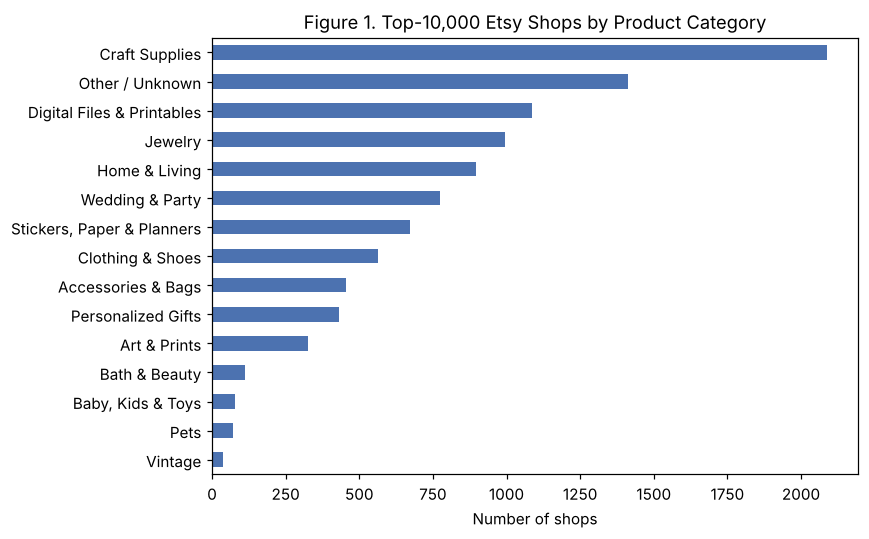

In [11]:
# Figure 1: number of top shops per category
fig, ax = plt.subplots(figsize=(8, 5))
summary['shops'].sort_values().plot.barh(ax=ax, color='#4C72B0')
ax.set_title('Figure 1. Top-10,000 Etsy Shops by Product Category')
ax.set_xlabel('Number of shops')
ax.set_ylabel('')
plt.tight_layout(); plt.savefig(FIG_DIR + 'fig1_categories.png', bbox_inches='tight'); plt.show()

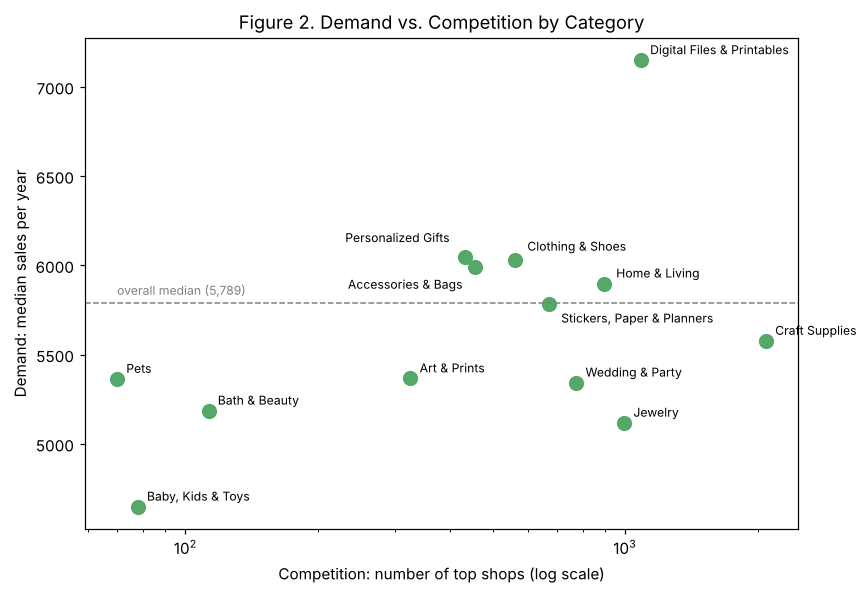

In [12]:
# Figure 2: demand vs. competition
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(ranked['shops'], ranked['median_sales_per_year'], s=80, color='#55A868')
offsets = {'Personalized Gifts': (-10, 10), 'Clothing & Shoes': (8, 6), 'Accessories & Bags': (-8, -14),
           'Home & Living': (8, 4), 'Stickers, Paper & Planners': (8, -12)}
for name, r in ranked.iterrows():
    dx, dy = offsets.get(name, (6, 4))
    ax.annotate(name, (r['shops'], r['median_sales_per_year']), textcoords='offset points',
                xytext=(dx, dy), fontsize=8, ha='right' if dx < 0 else 'left')
ax.axhline(overall_demand, color='gray', ls='--', lw=1)
ax.text(ranked['shops'].min(), overall_demand + 30, f'overall median ({overall_demand:,.0f})', ha='left', va='bottom', fontsize=8, color='gray')
ax.set_xscale('log')
ax.set_xlabel('Competition: number of top shops (log scale)')
ax.set_ylabel('Demand: median sales per year')
ax.set_title('Figure 2. Demand vs. Competition by Category')
plt.tight_layout(); plt.savefig(FIG_DIR + 'fig2_demand_competition.png', bbox_inches='tight'); plt.show()

## 5. Research question 2: which shop features go with higher sales?
Spearman correlation is used because sales are very skewed (a few shops sell far more than the rest), and Spearman works on ranks instead of raw values.

digital_share          -0.008
average_rating          0.005
ships_to_countries      0.042
shop_age_years          0.066
active_listing_count    0.233
favorites_count         0.399
total_rating_count      0.667
Name: sold_count, dtype: float64


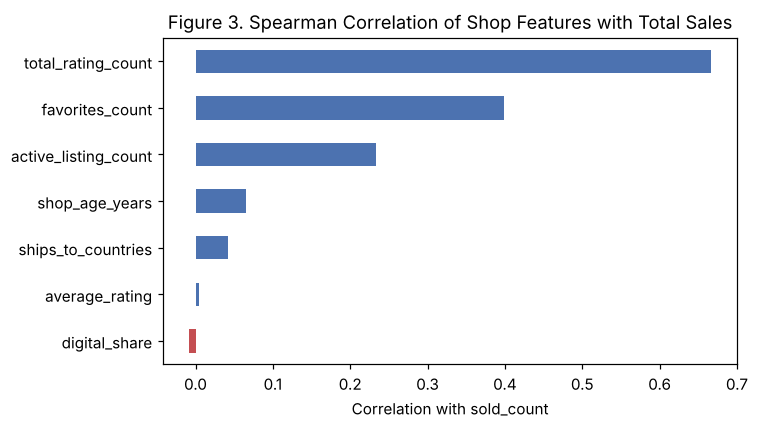

In [13]:
features_num = ['shop_age_years','active_listing_count','digital_share','average_rating',
                'ships_to_countries','favorites_count','total_rating_count']
corr = df[features_num + ['sold_count']].corr(method='spearman')['sold_count'].drop('sold_count').sort_values()
print(corr.round(3))

fig, ax = plt.subplots(figsize=(7, 4))
corr.plot.barh(ax=ax, color=['#C44E52' if v < 0 else '#4C72B0' for v in corr])
ax.set_title('Figure 3. Spearman Correlation of Shop Features with Total Sales')
ax.set_xlabel('Correlation with sold_count')
plt.tight_layout(); plt.savefig(FIG_DIR + 'fig3_correlations.png', bbox_inches='tight'); plt.show()

In [14]:
cutoff = df['sold_count'].quantile(0.75)
df['top_seller'] = (df['sold_count'] >= cutoff).astype(int)
print(f'Top-seller cutoff (75th percentile): {cutoff:,.0f} items sold')
num_cols = ['shop_age_years','active_listing_count','digital_share','average_rating','ships_to_countries']
bool_cols = ['additional_customization','has_free_shipping','is_us']
compare = pd.concat([df.groupby('top_seller')[num_cols].median().add_prefix('median_'),
                     df.groupby('top_seller')[bool_cols].mean().add_prefix('pct_')], axis=1).T
compare.columns = ['Not top seller', 'Top seller']
compare.round(3)

Top-seller cutoff (75th percentile): 56,341 items sold


,Not top seller,Top seller
median_shop_age_years,7.354,7.677
median_active_listing_count,370.000,665.000
median_digital_share,0.000,0.000
median_average_rating,4.924,4.922
median_ships_to_countries,7.000,9.000
pct_additional_customization,0.454,0.581
pct_has_free_shipping,0.515,0.575
pct_is_us,0.621,0.658


## 6. Research question 3: predicting top sellers
**Target:** `top_seller` (1 = top 25% of total sales within the top-10,000 group).

**Features:** things a seller can control or knows when starting out: shop age, number of listings, digital share, average rating, customization, free shipping, U.S. location, number of shipping countries, and category.

**Left out on purpose:** `favorites_count` and `total_rating_count`. These grow *because* a shop sells more, so using them would leak the answer into the model and make it look better than it really is.

**Models:**
- Logistic regression (simple and easy to explain), scaled and with balanced class weights.
- Random forest (handles non-linear patterns and interactions), with balanced class weights.

Only 25% of shops are top sellers, so a model that always says "not a top seller" would already be 75% accurate. That is why the main metrics are **ROC AUC** and **balanced accuracy**, not plain accuracy.

In [15]:
model_df = df.copy()
model_df['log_listings'] = np.log1p(model_df['active_listing_count'])
X = pd.get_dummies(model_df[['shop_age_years','log_listings','digital_share','average_rating',
                             'additional_customization','has_free_shipping','free_shipping_unknown',
                             'is_us','ships_to_countries','category']],
                   columns=['category'], drop_first=True).astype(float)
y = model_df['top_seller']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print('Train:', X_train.shape, ' Test:', X_test.shape, ' Top-seller rate:', round(y.mean(), 3))

Train: (7994, 23)  Test: (1999, 23)  Top-seller rate: 0.25


In [16]:
models = {
    'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight='balanced')),
    'Random Forest': RandomForestClassifier(n_estimators=400, max_depth=8, min_samples_leaf=10,
                                            class_weight='balanced', random_state=42, n_jobs=-1),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_rows = []
for name, model in models.items():
    s = cross_validate(model, X_train, y_train, cv=cv, scoring=['roc_auc','balanced_accuracy','accuracy'])
    cv_rows.append({'model': name,
                    'CV ROC AUC': s['test_roc_auc'].mean(), 'AUC std': s['test_roc_auc'].std(),
                    'CV balanced accuracy': s['test_balanced_accuracy'].mean(),
                    'CV accuracy': s['test_accuracy'].mean()})
cv_results = pd.DataFrame(cv_rows).set_index('model')
cv_results.round(3)

,CV ROC AUC,AUC std,CV balanced accuracy,CV accuracy
model,,,,
Logistic Regression,0.648,0.019,0.599,0.593
Random Forest,0.666,0.023,0.620,0.666


In [17]:
test_rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test); prob = model.predict_proba(X_test)[:, 1]
    test_rows.append({'model': name, 'Test ROC AUC': roc_auc_score(y_test, prob),
                      'Test balanced accuracy': balanced_accuracy_score(y_test, pred),
                      'Test accuracy': (pred == y_test).mean()})
test_results = pd.DataFrame(test_rows).set_index('model')
best_name = test_results['Test ROC AUC'].idxmax()
best = models[best_name]
print('Best model on test AUC:', best_name)
test_results.round(3)

Best model on test AUC: Random Forest


,Test ROC AUC,Test balanced accuracy,Test accuracy
model,,,
Logistic Regression,0.634,0.597,0.593
Random Forest,0.662,0.623,0.675


                precision    recall  f1-score   support

Not top seller       0.82      0.73      0.77      1499
    Top seller       0.39      0.52      0.44       500

      accuracy                           0.67      1999
     macro avg       0.60      0.62      0.61      1999
  weighted avg       0.71      0.67      0.69      1999



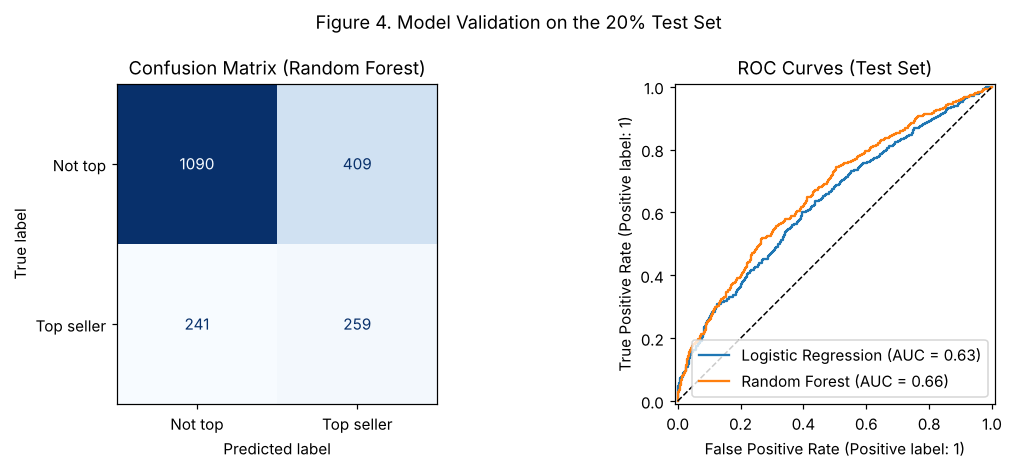

In [18]:
pred = best.predict(X_test)
print(classification_report(y_test, pred, target_names=['Not top seller','Top seller']))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=['Not top','Top seller']).plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title(f'Confusion Matrix ({best_name})')
for name, model in models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, ax=axes[1], name=name)
axes[1].plot([0, 1], [0, 1], 'k--', lw=1)
axes[1].set_title('ROC Curves (Test Set)')
fig.suptitle('Figure 4. Model Validation on the 20% Test Set')
plt.tight_layout(); plt.savefig(FIG_DIR + 'fig4_validation.png', bbox_inches='tight'); plt.show()

Logistic regression coefficients (scaled features):
category_Home & Living                -0.127
category_Art & Prints                 -0.098
category_Vintage                      -0.066
category_Personalized Gifts           -0.048
category_Other / Unknown              -0.038
category_Jewelry                      -0.035
category_Stickers, Paper & Planners   -0.030
category_Baby, Kids & Toys            -0.029
category_Clothing & Shoes             -0.019
category_Digital Files & Printables    0.003
category_Pets                          0.009
ships_to_countries                     0.020
category_Wedding & Party               0.023
average_rating                         0.024
digital_share                          0.025
category_Bath & Beauty                 0.040
free_shipping_unknown                  0.048
has_free_shipping                      0.054
category_Craft Supplies                0.073
is_us                                  0.089
shop_age_years                         0.112
add

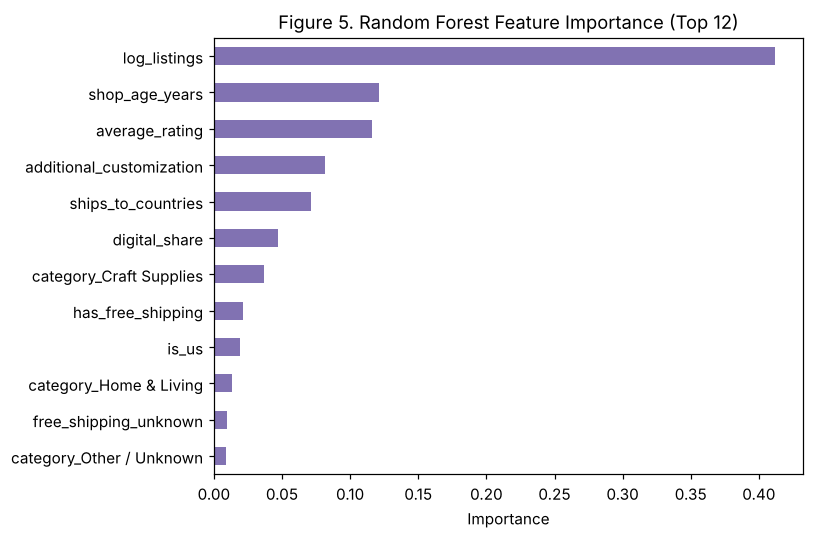

In [19]:
rf = models['Random Forest']
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values().tail(12)
lr = models['Logistic Regression'][-1]
coefs = pd.Series(lr.coef_[0], index=X.columns).sort_values()
print('Logistic regression coefficients (scaled features):')
print(coefs.round(3))

fig, ax = plt.subplots(figsize=(7.5, 5))
imp.plot.barh(ax=ax, color='#8172B2')
ax.set_title('Figure 5. Random Forest Feature Importance (Top 12)')
ax.set_xlabel('Importance')
plt.tight_layout(); plt.savefig(FIG_DIR + 'fig5_importance.png', bbox_inches='tight'); plt.show()

## 7. Summary of results
The printed tables above give the exact numbers used in the white paper:
- **RQ1:** the `ranked` table and Figure 2 show which categories have high demand relative to competition.
- **RQ2:** the correlations (Figure 3) and the top-seller comparison table show which features go with higher sales.
- **RQ3:** the cross-validation and test tables, confusion matrix, and ROC curves (Figure 4) show how well top sellers can be predicted, and Figure 5 shows which features the model relies on.

**Limitations to keep in mind:** the data only covers shops that were already in the top 10,000 on one day in April 2022, sales are lifetime totals (not profit), and categories come from keyword matching, so some shops may be placed in the wrong group.